# Multilayer perceptron with back-propagation from scratch (NumPy)

Neural-networks course exercise: a fully connected network with an arbitrary number of hidden layers, implemented
without any deep-learning framework — forward pass, back-propagation of the error through the activation
derivatives, and per-sample (online) gradient-descent updates.

Experiments on the **Iris** dataset (4 features, 3 one-hot classes, 67/33 split) compare activation functions,
hidden-layer sizes, depth and learning rate. The score printed after each experiment is scikit-learn's
**average precision** of the network outputs against the one-hot labels (micro-averaged), not classification accuracy.

| Experiment | Hidden layers | Activation | Learning rate | Average precision |
|---|---|---|---|---|
| Baseline | [3] | sigmoid | 0.01 | 0.759 |
| Linear activation | [3] | linear | 0.01 | 0.777 |
| Wider | [6] | sigmoid | 0.01 | **0.986** |
| Deeper | [3, 3] | sigmoid | 0.01 | 0.487 |
| Larger learning rate | [3] | sigmoid | 0.1 | 0.759 |

Weights are initialised uniformly in [0, 1) without a fixed seed, so re-running gives slightly different numbers.


In [ ]:
import numpy as np


class MLP(object):
    def __init__(self,activation, num_inputs=3, hidden_layers=[3, 3], num_outputs=2 ):

        self.num_inputs = num_inputs
        self.hidden_layers = hidden_layers
        self.num_outputs = num_outputs
        self.activation = activation
        self.error_history = []


        layers = [num_inputs] + hidden_layers + [num_outputs]

        weights = []
        for i in range(len(layers) - 1):
            w = np.random.rand(layers[i], layers[i + 1])
            weights.append(w)
        self.weights = weights

        derivatives = []
        for i in range(len(layers) - 1):
            d = np.zeros((layers[i], layers[i + 1]))
            derivatives.append(d)
        self.derivatives = derivatives


        y = []
        for i in range(len(layers)):
            a = np.zeros(layers[i])
            y.append(a)
        self.y = y


    def forward_propagate(self, inputs):

        y = inputs

        self.y[0] = y

        for i, w in enumerate(self.weights):

            net_inputs = np.dot(y, w)

            y = self.activation(net_inputs)

            self.y[i + 1] = y

        return y


    def back_propagate(self, error):
      

        for i in reversed(range(len(self.derivatives))):

            # get activation for previous layer
            y = self.y[i+1]

            # apply activation derivative function
            delta = error * self.activation(y,deriv=True)

            # reshape delta as to have it as a 2d array
            delta_re = delta.reshape(delta.shape[0], -1).T

            # get y for current layer
            current_y = self.y[i]

            # reshape y as to have them as a 2d column matrix
            current_y = current_y.reshape(current_y.shape[0],-1)

            # save derivative after applying matrix multiplication
            self.derivatives[i] = np.dot(current_y, delta_re)

            # backpropogate the next error
            error = np.dot(delta, self.weights[i].T)


    def train(self, inputs, targets, epochs, learning_rate):
        """Trains model running forward prop and backprop
        Args:
            inputs (ndarray): X
            targets (ndarray): Y
            epochs (int): Num. epochs we want to train the network for
            learning_rate (float): Step to apply to gradient descent
        """
        # now enter the training loop
        for i in range(epochs):
            sum_errors = 0

            # iterate through all the training data
            for j, input in enumerate(inputs):
                target = targets[j]

                # activate the network!
                output = self.forward_propagate(input)

                error = target - output

                self.back_propagate(error)

                # now perform gradient descent on the derivatives
                # (this will update the weights
                self.gradient_descent(learning_rate)

                # keep track of the MSE for reporting later
                sum_errors += self._mse(target, output)

            # Epoch complete, report the training error
            self.error_history.append(sum_errors / len(inputs))



    def gradient_descent(self, learningRate=1):
        """Learns by descending the gradient
        Args:
            learningRate (float): How fast to learn.
        """
        # update the weights by stepping down the gradient
        for i in range(len(self.weights)):
            weights = self.weights[i]
            derivatives = self.derivatives[i]
            weights += derivatives * learningRate




    def _mse(self, target, output):
        """Mean Squared Error loss function
        Args:
            target (ndarray): The ground trut
            output (ndarray): The predicted values
        Returns:
            (float): Output
        """
        return np.average((target - output) ** 2)

      

In [ ]:
#activation function ==> f(x) = 1/1+e^(-x)
def sigmoid(x, deriv=False):
    if deriv == True:
        return x * (1.0 - x)
    y = 1.0 / (1 + np.exp(-x))
    return y

#activation function ==> f(x) = x
def linear(x, deriv=False):
    if deriv == True:
        return 1
    return x

In [ ]:
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import average_precision_score
iris = datasets.load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)
oh = OneHotEncoder()
oh.fit(y)
y=oh.transform(y).toarray()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=4)

## Baseline

activation_function = sigmoid

learning rate (miu) = 0.01

mlp shape = (input : 4, hidden : [3], output: 3)

average precision: 0.758532745493025


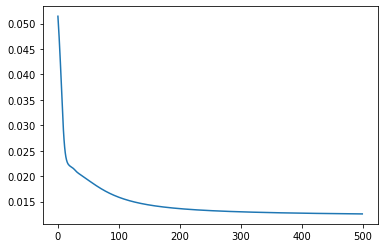

In [ ]:
# input data
inputs = X_train
# output data
outputs = y_train
# activation function
activation_function = sigmoid
# learning rate
miu = 0.01
# number of epochs
epochs=500
# create neural network   
mlp = MLP(activation_function ,4, [3], 3)
# train network
mlp.train(inputs, y_train, epochs, miu)
#plot error
plt.plot(range(epochs),mlp.error_history )
#test network
output = mlp.forward_propagate(X_test)
# print the predictions for test data                                   
print('average precision:', average_precision_score(y_test, output))

## Linear activation

average precision: 0.7768217808751782


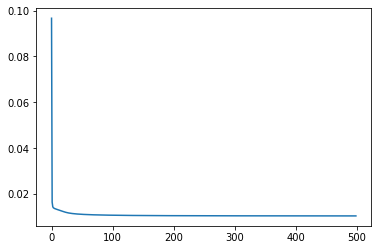

In [ ]:
activation_function = linear
# learning rate
miu = 0.01
# number of epochs
epochs=500
# create neural network   
mlp = MLP(activation_function ,4, [3], 3)
# train network
mlp.train(inputs, y_train, epochs, miu)
#plot error
plt.plot(range(epochs),mlp.error_history )
#test network
output = mlp.forward_propagate(X_test)
# print the predictions for test data                                   
print('average precision:', average_precision_score(y_test, output))

## Wider hidden layer: (4, [6], 3)

average precision: 0.9864464674758793


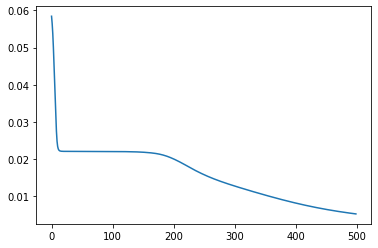

In [ ]:
# input data
inputs = X_train
# output data
outputs = y_train
# activation function
activation_function = sigmoid
# learning rate
miu = 0.01
# number of epochs
epochs=500
# create neural network   
mlp = MLP(activation_function ,4, [6], 3)
# train network
mlp.train(inputs, y_train, epochs, miu)
#plot error
plt.plot(range(epochs),mlp.error_history )
#test network
output = mlp.forward_propagate(X_test)
# print the predictions for test data                                   
print('average precision:', average_precision_score(y_test, output))

## Two hidden layers: (4, [3, 3], 3)

average precision: 0.48734662644907134


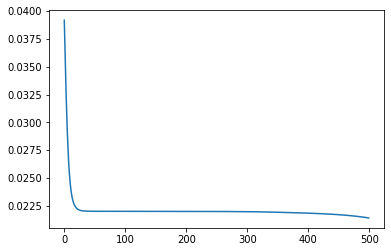

In [ ]:
# input data
inputs = X_train
# output data
outputs = y_train
# activation function
activation_function = sigmoid
# learning rate
miu = 0.01
# number of epochs
epochs=500
# create neural network   
mlp = MLP(activation_function ,4, [3,3], 3)
# train network
mlp.train(inputs, y_train, epochs, miu)
#plot error
plt.plot(range(epochs),mlp.error_history )
#test network
output = mlp.forward_propagate(X_test)
# print the predictions for test data                                   
print('average precision:', average_precision_score(y_test, output))

## Learning rate 0.1

average precision: 0.758532745493025


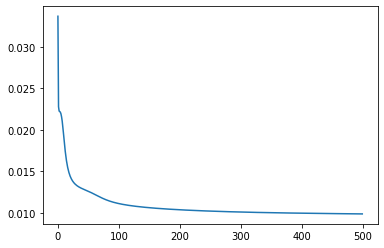

In [ ]:
# input data
inputs = X_train
# output data
outputs = y_train
# activation function
activation_function = sigmoid
# learning rate
miu = 0.1
# number of epochs
epochs=500
# create neural network   
mlp = MLP(activation_function ,4, [3], 3)
# train network
mlp.train(inputs, y_train, epochs, miu)
#plot error
plt.plot(range(epochs),mlp.error_history )
#test network
output = mlp.forward_propagate(X_test)
# print the predictions for test data                                   
print('average precision:', average_precision_score(y_test, output))